# 04 · Exercise Physiology: Exploratory Analysis

**How do wearable physiological signals respond to acute stress, aerobic exercise and anaerobic sprints?**

All analyses use the quality flags from notebook 02 (invalid signals are masked) and the analysis states from
notebook 03. Every summary is computed **participant-first**: windows are averaged within each person, and the
group statistics then treat each participant as one observation.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

from src.signals.quality import masked_features
from src.features.profiles import event_traces, summarise

w = pd.read_csv(PROCESSED / "windows.csv")
m = masked_features(w)
seg = pd.read_csv(INTERIM / "segments.csv")
STATES = ["REST_SEATED", "STRESS_TMCT", "STRESS_RECOVERY", "AEROBIC_MODERATE", "AEROBIC_PEAK", "SPRINT", "POST_SPRINT", "POST_EXERCISE_REST"]
LABEL = {"REST_SEATED": "Seated rest", "STRESS_TMCT": "Stress (TMCT)", "STRESS_RECOVERY": "Stress recovery",
         "STRESS_SHORT": "Short stress tasks", "AEROBIC_MODERATE": "Aerobic moderate", "AEROBIC_PEAK": "Aerobic peak",
         "SPRINT": "Sprint", "POST_SPRINT": "Post-sprint 0-2 min", "POST_EXERCISE_REST": "Post-exercise rest"}
SCOL = {"REST_SEATED": P.TEXT_2, "STRESS_TMCT": C["STRESS"], "STRESS_RECOVERY": C["STRESS"], "STRESS_SHORT": C["STRESS"],
        "AEROBIC_MODERATE": C["AEROBIC"], "AEROBIC_PEAK": C["AEROBIC"], "SPRINT": C["ANAEROBIC"],
        "POST_SPRINT": C["ANAEROBIC"], "POST_EXERCISE_REST": P.TEXT_2}
FEATS = ["hr_mean", "eda_tonic_mean", "eda_scr_rate", "temp_slope", "acc_movement"]
pm = m[m.analysis_state.notna()].groupby(["subject_id", "cohort", "analysis_state"])[FEATS].mean().reset_index()
pm.to_csv(PROCESSED / "participant_state_means.csv", index=False)
print(pm.groupby("analysis_state").subject_id.nunique().reindex(STATES).rename("participants"))

analysis_state
REST_SEATED           36
STRESS_TMCT           36
STRESS_RECOVERY       36
AEROBIC_MODERATE      30
AEROBIC_PEAK          30
SPRINT                31
POST_SPRINT           31
POST_EXERCISE_REST    31
Name: participants, dtype: int64


## 1 · The same signals, five physiological states

Each grey line is one participant. Black is the median across participants. Panels share states on the x-axis.

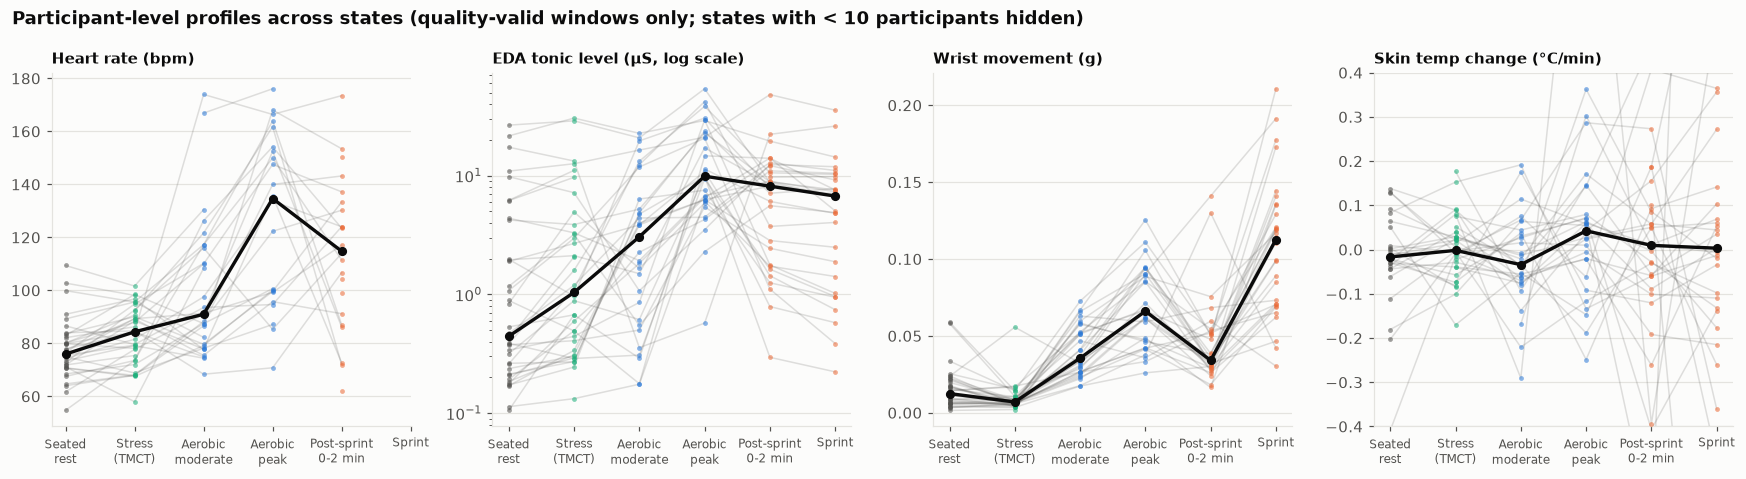

,hr_mean,eda_tonic_mean,eda_scr_rate,temp_slope,acc_movement
analysis_state,,,,,
REST_SEATED,75.950,0.444,0.179,-0.017,0.012
STRESS_TMCT,84.342,1.038,1.181,-0.002,0.007
STRESS_RECOVERY,72.313,0.508,0.096,0.012,0.009
AEROBIC_MODERATE,90.986,3.051,4.057,-0.034,0.036
AEROBIC_PEAK,134.666,9.880,7.571,0.042,0.066
SPRINT,110.951,6.722,7.000,0.003,0.113
POST_SPRINT,114.751,8.148,6.952,0.010,0.034
POST_EXERCISE_REST,111.237,11.799,4.923,-0.041,0.025


In [2]:
show = ["REST_SEATED", "STRESS_TMCT", "AEROBIC_MODERATE", "AEROBIC_PEAK", "POST_SPRINT", "SPRINT"]
panels = [("hr_mean", "Heart rate (bpm)"), ("eda_tonic_mean", "EDA tonic level (µS, log scale)"),
          ("acc_movement", "Wrist movement (g)"), ("temp_slope", "Skin temp change (°C/min)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
x = np.arange(len(show))
for ax, (f, lab) in zip(axes, panels):
    wide = pm.pivot_table(index="subject_id", columns="analysis_state", values=f).reindex(columns=show)
    for s_ in show:                      # hide states with < 10 participants with valid data
        if wide[s_].notna().sum() < 10:
            wide[s_] = np.nan
    for _, row in wide.iterrows():
        ax.plot(x, row.values, color=P.TEXT_2, alpha=0.18, lw=1)
    for i, s in enumerate(show):
        v = wide[s].dropna()
        ax.scatter(np.full(len(v), i), v, s=10, color=SCOL[s], alpha=0.55, lw=0, zorder=3)
    ax.plot(x, wide.median().values, color=P.TEXT, lw=2.2, marker="o", ms=5, zorder=4)
    ax.set_xticks(x, [LABEL[s].replace(" ", "\n", 1) for s in show], fontsize=8)
    ax.set_title(lab, loc="left", fontsize=10); ax.grid(axis="x", visible=False)
    if f == "eda_tonic_mean": ax.set_yscale("log")
    if f == "temp_slope": ax.set_ylim(-0.4, 0.4)
fig.suptitle("Participant-level profiles across states (quality-valid windows only; states with < 10 participants hidden)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "04_state_profiles"); plt.show()
pm.groupby("analysis_state")[FEATS].median().reindex(STATES).round(3)

What the data show (each person counts once):
- **Heart rate** rises modestly during the TMCT relative to seated rest (median 76 → 84 bpm) and much more in
  exercise: 91 bpm at moderate aerobic stages, 135 bpm at the aerobic peak, 115 bpm in the 2 min after sprints.
  During sprints only 3 participants have any valid HR, so that state is hidden.
- **EDA** rises with stress in the seated condition, but by an order of magnitude more during exercise
  (thermoregulatory sweating). That is why the panel uses a log scale. EDA level alone cannot distinguish "stressed"
  from "exercising". The context signal does that.
- **Movement** separates seated states from pedalling, and sprints from everything else. During the stress task
  participants move *less* than at rest (0.007 vs 0.012 g): they sit still and concentrate. Movement carries no
  information about the stress response itself.
- **Skin-temperature slope** is close to zero in every state at the group level, with large individual scatter (the
  axis is clipped at ±0.4 °C/min). Skin temperature is the least informative signal in this dataset.

## 2 · Event-locked responses: stress task vs sprint

Traces are aligned to the start of the TMCT (stress) or of each sprint, binned in 5 s and expressed as change from the
60 s before onset. Within each participant, all sprints are averaged first. Shaded = 95% CI across participants
(bins with < 5 participants are hidden). HR uses quality-valid samples only.

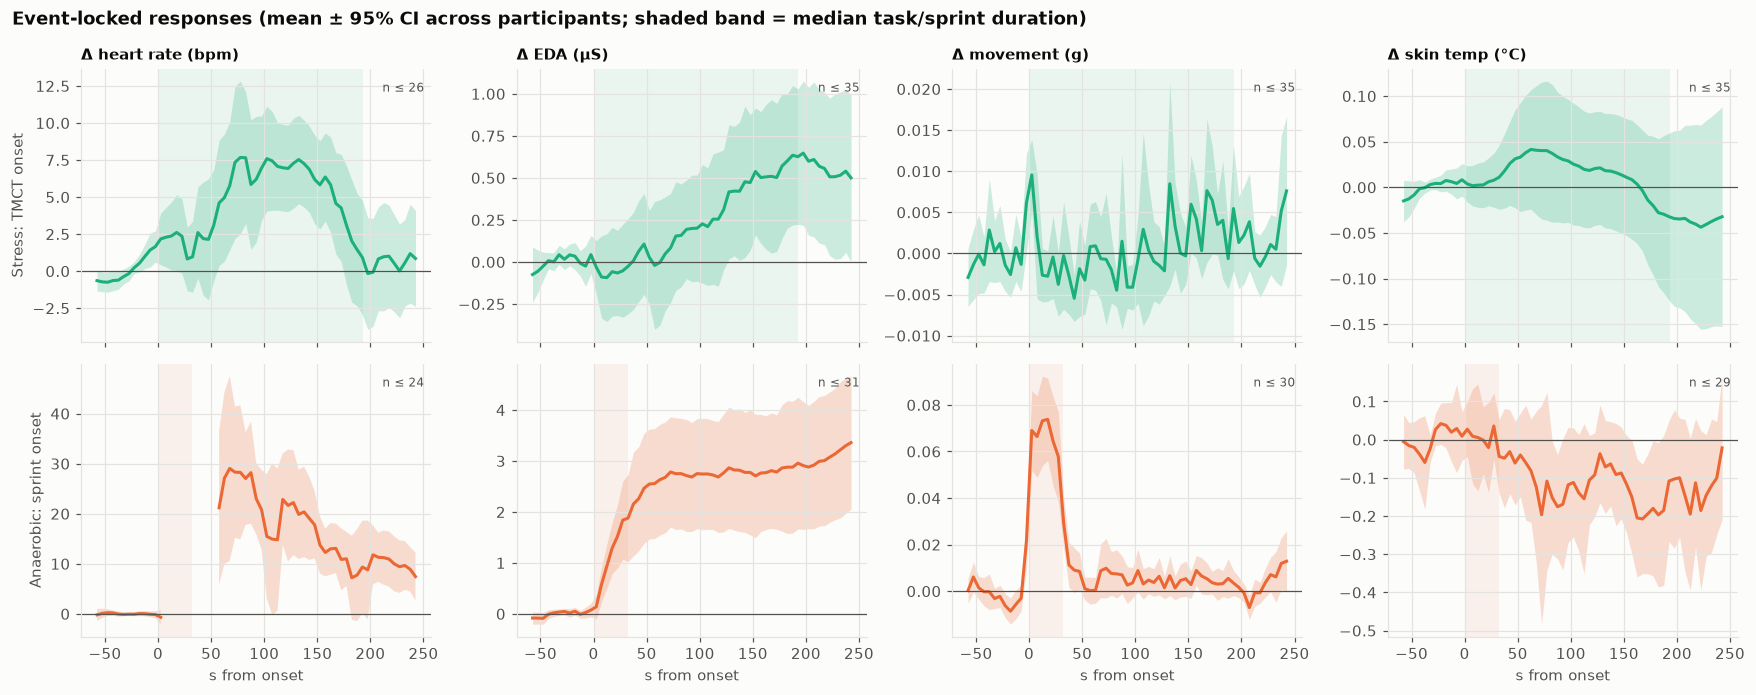

HR        peak change  TMCT: (np.float64(7.67), np.float64(77.5), 20)   sprint: (np.float64(29.04), np.float64(67.5), 5)   (value, time s, n)
EDA       peak change  TMCT: (np.float64(0.65), np.float64(197.5), 35)   sprint: (np.float64(3.3), np.float64(237.5), 31)   (value, time s, n)
Movement  peak change  TMCT: (np.float64(0.01), np.float64(2.5), 35)   sprint: (np.float64(0.07), np.float64(17.5), 30)   (value, time s, n)
TEMP      peak change  TMCT: (np.float64(-0.04), np.float64(222.5), 35)   sprint: (np.float64(-0.21), np.float64(167.5), 29)   (value, time s, n)


In [3]:
ev_stress = seg[(seg.condition == "STRESS") & (seg.segment == "tmct")].assign(event="TMCT", onset_s=lambda d: d.start_s)
ev_sprint = seg[(seg.condition == "ANAEROBIC") & seg.segment.str.startswith("sprint")].assign(event="Sprint", onset_s=lambda d: d.start_s)
ev_stress = ev_stress[ev_stress.session_id != "f07"]  # PPG/TEMP covered; EDA kept below via separate run is unnecessary
tr_stress = event_traces(ev_stress, w, pre_s=60, post_s=240)
tr_sprint = event_traces(ev_sprint, w, pre_s=60, post_s=240)
tr_stress.to_csv(PROCESSED / "event_traces_tmct.csv", index=False); tr_sprint.to_csv(PROCESSED / "event_traces_sprint.csv", index=False)
s_st, s_sp = summarise(tr_stress), summarise(tr_sprint)

sig = [("HR", "Δ heart rate (bpm)"), ("EDA", "Δ EDA (µS)"), ("Movement", "Δ movement (g)"), ("TEMP", "Δ skin temp (°C)")]
med_tmct = seg[(seg.condition == "STRESS") & (seg.segment == "tmct")].duration_s.median()
med_sprint = seg[(seg.condition == "ANAEROBIC") & seg.segment.str.startswith("sprint")].duration_s.median()
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), sharex=True)
for row, (s, col, name, dur) in enumerate([(s_st, C["STRESS"], "Stress: TMCT onset", med_tmct),
                                          (s_sp, C["ANAEROBIC"], "Anaerobic: sprint onset", med_sprint)]):
    for j, (k, lab) in enumerate(sig):
        ax = axes[row, j]; d = s[s.signal == k]
        ax.axvspan(0, dur, color=col, alpha=0.08, lw=0)
        ax.fill_between(d.t, d.low, d.high, color=col, alpha=0.22, lw=0)
        ax.plot(d.t, d["mean"], color=col, lw=2)
        ax.axhline(0, color=P.TEXT_2, lw=0.8)
        if row == 0: ax.set_title(lab, loc="left", fontsize=10)
        if j == 0: ax.set_ylabel(name, fontsize=10)
        nmax = int(d.n.max()) if len(d) else 0
        ax.text(0.98, 0.95, f"n ≤ {nmax}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=P.TEXT_2)
for ax in axes[1]: ax.set_xlabel("s from onset")
fig.suptitle("Event-locked responses (mean ± 95% CI across participants; shaded band = median task/sprint duration)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "04_event_locked"); plt.show()

def peak(s, k, t0=0, t1=240):
    d = s[(s.signal == k) & (s.t > t0) & (s.t <= t1)].dropna(subset=["mean"])
    if d.empty: return (np.nan, np.nan, 0)
    r = d.loc[d["mean"].abs().idxmax()]
    return (round(r["mean"], 2), r.t, int(r.n))
for k, _ in sig:
    print(f"{k:9s} peak change  TMCT: {peak(s_st, k)}   sprint: {peak(s_sp, k)}   (value, time s, n)")

- **Stress (TMCT):** HR rises over the first minute and plateaus around **+6 to +7 bpm** (95% CI excludes zero from
  ~60 to ~160 s), with **no change in movement**. It returns to baseline as the task ends. EDA climbs steadily, by
  about +0.6 µS by the end of the task. Skin temperature does not change meaningfully (CI spans zero). This is a
  physiological arousal response with no mechanical cause: the core of the "physiological state ≠ movement" argument.
- **Sprint:** movement jumps during the sprint and returns to baseline immediately. EDA rises by ~2.5 µS within a
  minute and keeps climbing during the unloaded cooldown. Skin temperature *falls* by ~0.1–0.2 °C, consistent with
  sweat evaporation and airflow. **HR during and just after the sprint cannot be measured from the wrist**: the
  first valid post-sprint samples appear at ~60 s, at roughly +25–30 bpm, then decline over the next 3 min. That
  curve rests on only **5–15 participants** (n shown per panel), so it is descriptive.

## 3 · Aerobic incremental test: stage-by-stage (cohort V1, 10 prescribed stages)

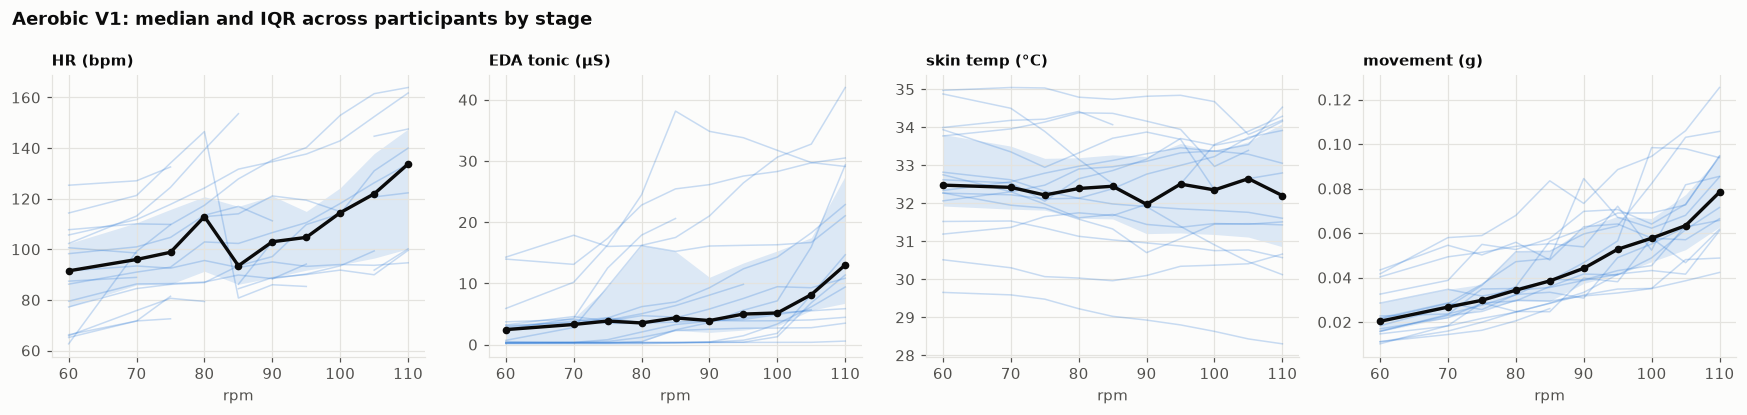

hr_mean         median per-participant rho with stage = 0.95  (n = 15)
eda_tonic_mean  median per-participant rho with stage = 0.99  (n = 17)
temp_mean       median per-participant rho with stage = -0.48  (n = 16)
acc_movement    median per-participant rho with stage = 0.98  (n = 17)


In [4]:
a = m[(m.condition == "AEROBIC") & (m.cohort == "V1") & m.segment.str.match(r"rpm_\d+$")].copy()
a["rpm"] = a.segment.str[4:].astype(int)
per = a.groupby(["subject_id", "rpm"])[["hr_mean", "eda_tonic_mean", "temp_mean", "acc_movement"]].mean().reset_index()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (f, lab) in zip(axes, [("hr_mean", "HR (bpm)"), ("eda_tonic_mean", "EDA tonic (µS)"),
                               ("temp_mean", "skin temp (°C)"), ("acc_movement", "movement (g)")]):
    wide = per.pivot(index="subject_id", columns="rpm", values=f)
    for _, row in wide.iterrows():
        ax.plot(wide.columns, row.values, color=C["AEROBIC"], alpha=0.25, lw=1)
    q = wide.quantile([0.25, 0.5, 0.75])
    ax.fill_between(wide.columns, q.loc[0.25], q.loc[0.75], color=C["AEROBIC"], alpha=0.15, lw=0)
    ax.plot(wide.columns, q.loc[0.5], color=P.TEXT, lw=2.2, marker="o", ms=4)
    ax.set_title(lab, loc="left", fontsize=10); ax.set_xlabel("rpm")
fig.suptitle("Aerobic V1: median and IQR across participants by stage", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "04_aerobic_stages"); plt.show()
from scipy.stats import spearmanr
for f in ["hr_mean", "eda_tonic_mean", "temp_mean", "acc_movement"]:
    r = per.dropna(subset=[f]).groupby("subject_id").apply(lambda g: spearmanr(g.rpm, g[f]).statistic if len(g) >= 4 else np.nan, include_groups=False)
    print(f"{f:15s} median per-participant rho with stage = {r.median():.2f}  (n = {r.notna().sum()})")

HR, EDA and movement all rise with stage (median per-participant rank correlation 0.95, 0.99 and 0.98). Two patterns
are worth a physiologist's attention:
- **EDA is not linear**: it barely changes up to ~95 rpm, then rises steeply in the last stages. That is consistent
  with a **sweating threshold**: thermoregulatory sweating starts only once heat production has accumulated.
- **Skin temperature does not rise** with workload. It is flat at the group level and *falls* within most
  participants (median ρ = −0.48), consistent with cutaneous vasoconstriction during exercise plus evaporative and
  convective cooling at the wrist.

The HR median dips at 85 rpm because a different subset of participants has valid HR at that stage (composition
effect, notebook 02).

## 4 · Aerobic vs anaerobic

Two very different exercise patterns: a long, progressive steady effort vs short all-out bursts separated by
unloaded recovery.

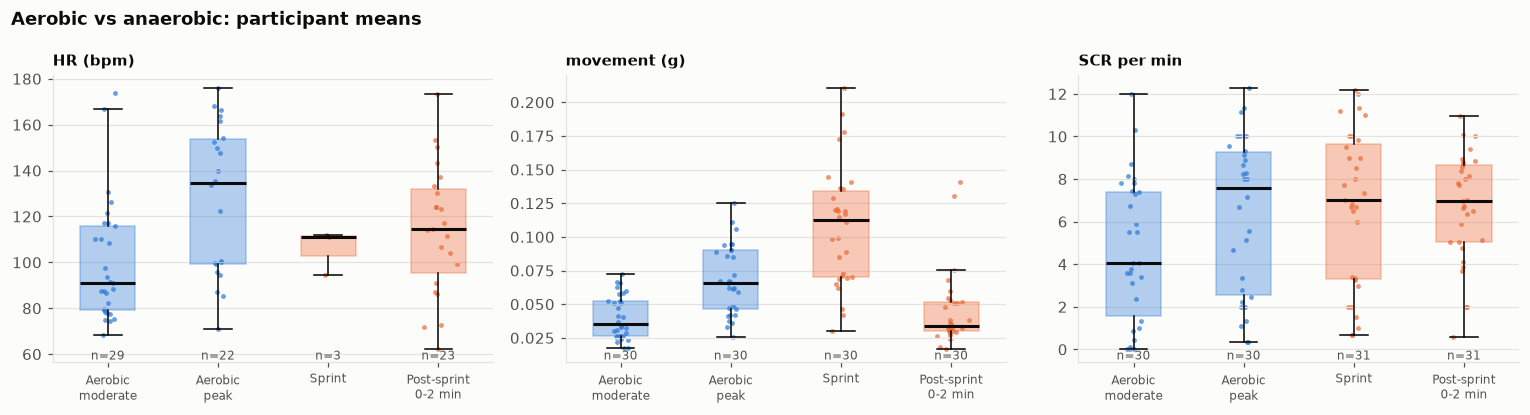

In [5]:
cmp_states = ["AEROBIC_MODERATE", "AEROBIC_PEAK", "SPRINT", "POST_SPRINT"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (f, lab) in zip(axes, [("hr_mean", "HR (bpm)"), ("acc_movement", "movement (g)"), ("eda_scr_rate", "SCR per min")]):
    data = [pm[pm.analysis_state == s][f].dropna() for s in cmp_states]
    bp = ax.boxplot(data, widths=0.5, showfliers=False, patch_artist=True, medianprops=dict(color=P.TEXT, lw=2))
    for patch, s in zip(bp["boxes"], cmp_states):
        patch.set_facecolor(SCOL[s]); patch.set_alpha(0.35); patch.set_edgecolor(SCOL[s])
    for i, d in enumerate(data):
        ax.scatter(np.random.default_rng(i).normal(i + 1, 0.05, len(d)), d, s=10, color=SCOL[cmp_states[i]], alpha=0.7, lw=0)
        ax.text(i + 1, ax.get_ylim()[0], f"n={len(d)}", ha="center", va="bottom", fontsize=8, color=P.TEXT_2)
    ax.set_xticks(range(1, 5), [LABEL[s].replace(" ", "\n", 1) for s in cmp_states], fontsize=8)
    ax.set_title(lab, loc="left", fontsize=10); ax.grid(axis="x", visible=False)
fig.suptitle("Aerobic vs anaerobic: participant means", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "04_aerobic_vs_anaerobic"); plt.show()

## 5 · Individual responses to the stress task

The change from each person's seated rest to the TMCT, on the same day, so no cross-day confound.

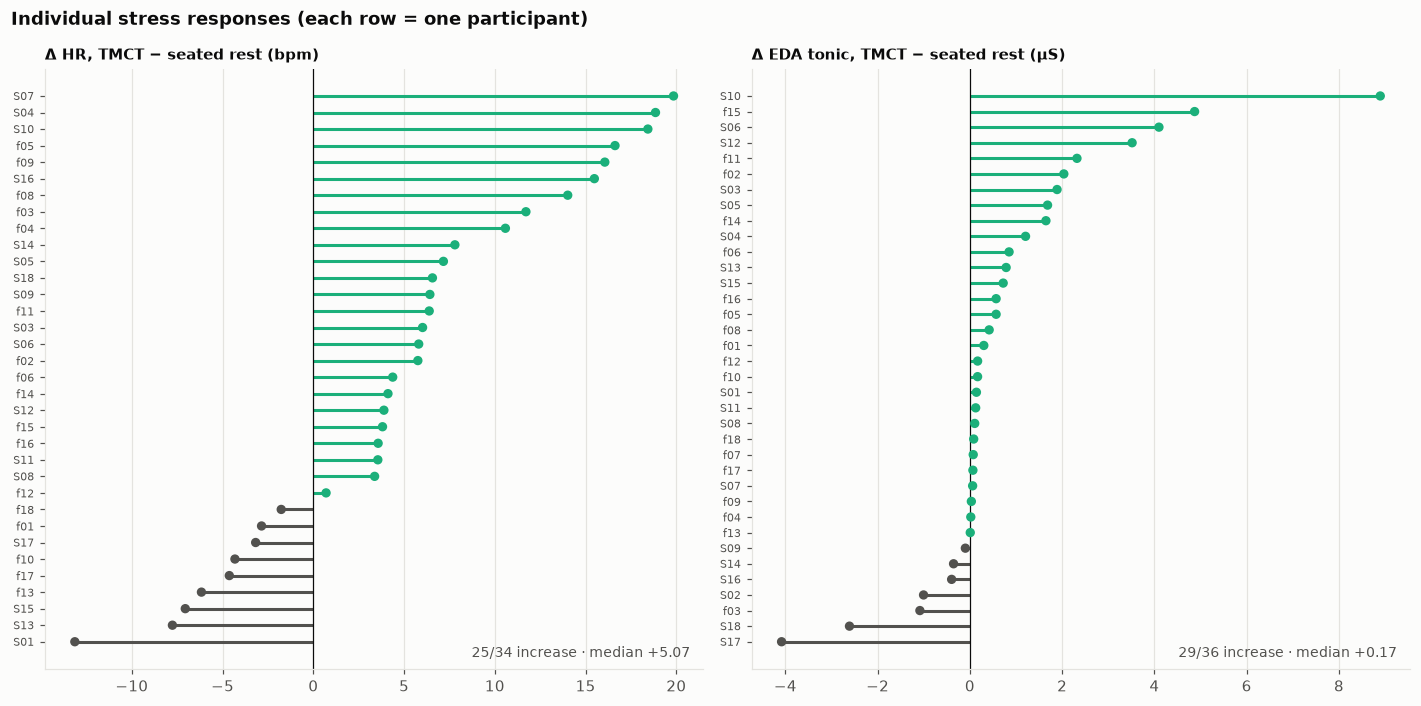

Correlation between HR and EDA responses (Spearman): 0.0 n = 34


In [6]:
wide_hr = pm.pivot_table(index="subject_id", columns="analysis_state", values="hr_mean")
wide_eda = pm.pivot_table(index="subject_id", columns="analysis_state", values="eda_tonic_mean")
resp = pd.DataFrame({"dHR": wide_hr.STRESS_TMCT - wide_hr.REST_SEATED,
                     "dEDA": wide_eda.STRESS_TMCT - wide_eda.REST_SEATED}).dropna(how="all")
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=False)
for ax, (k, lab) in zip(axes, [("dHR", "Δ HR, TMCT − seated rest (bpm)"), ("dEDA", "Δ EDA tonic, TMCT − seated rest (µS)")]):
    d = resp[k].dropna().sort_values()
    colors = [C["STRESS"] if v > 0 else P.TEXT_2 for v in d]
    ax.hlines(range(len(d)), 0, d.values, color=colors, lw=2)
    ax.scatter(d.values, range(len(d)), color=colors, s=26, zorder=3)
    ax.axvline(0, color=P.TEXT, lw=0.8)
    ax.set_yticks(range(len(d)), d.index, fontsize=7); ax.set_title(lab, loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.text(0.98, 0.02, f"{(d > 0).sum()}/{len(d)} increase · median {d.median():+.2f}", transform=ax.transAxes, ha="right", fontsize=9, color=P.TEXT_2)
fig.suptitle("Individual stress responses (each row = one participant)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "04_individual_stress_responses"); plt.show()
print("Correlation between HR and EDA responses (Spearman):", round(resp.corr(method="spearman").iloc[0, 1], 2), "n =", len(resp.dropna()))

Most participants respond to the TMCT with higher HR and EDA, but the size of the response varies several-fold
between people, and a minority show no response or a decrease. The HR and EDA responses are only loosely related
within a person: someone can be a strong "electrodermal responder" and a weak cardiac one. This is a reason to look
at the signals together rather than rely on one marker.

## 6 · Multimodal profile

A radar chart would imply a meaningful ordering and area between axes, which these features don't have. Instead,
each feature's participant-median per state is expressed as a z-score relative to the distribution across states, in
a heatmap with the raw medians printed in each cell.

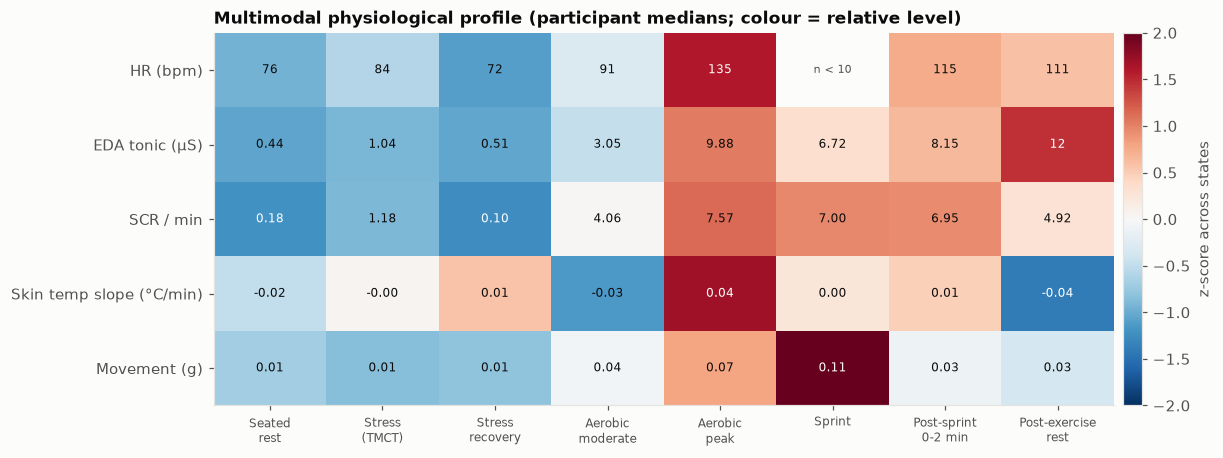

In [7]:
prof_feats = [("hr_mean", "HR (bpm)"), ("eda_tonic_mean", "EDA tonic (µS)"), ("eda_scr_rate", "SCR / min"),
              ("temp_slope", "Skin temp slope (°C/min)"), ("acc_movement", "Movement (g)")]
show = ["REST_SEATED", "STRESS_TMCT", "STRESS_RECOVERY", "AEROBIC_MODERATE", "AEROBIC_PEAK", "SPRINT", "POST_SPRINT", "POST_EXERCISE_REST"]
cols = [f for f, _ in prof_feats]
med = pm.groupby("analysis_state")[cols].median().reindex(show)
nval = pm.groupby("analysis_state")[cols].count().reindex(show)
med = med.where(nval >= 10)
z = (med - med.mean()) / med.std()
fig, ax = plt.subplots(figsize=(11, 4.4))
im = ax.imshow(z.T.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
for i in range(z.shape[1]):
    for j in range(z.shape[0]):
        v = med.iloc[j, i]
        if not np.isfinite(v):
            ax.text(j, i, "n < 10", ha="center", va="center", fontsize=7, color=P.TEXT_2); continue
        ax.text(j, i, f"{v:.2f}" if abs(v) < 10 else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if abs(z.iloc[j, i]) > 1.2 else P.TEXT)
ax.set_xticks(range(len(show)), [LABEL[s].replace(" ", "\n", 1) for s in show], fontsize=8)
ax.set_yticks(range(len(prof_feats)), [l for _, l in prof_feats]); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01); cb.set_label("z-score across states")
ax.set_title("Multimodal physiological profile (participant medians; colour = relative level)", loc="left")
P.save(fig, "04_multimodal_profile"); plt.show()

Each state has a distinct *combination* of signals. The stress task looks like rest on movement, but not on HR,
EDA level or SCR rate (≈ 6× more SCRs than at rest). Aerobic exercise combines rhythmic movement with high HR and rising EDA. Sprints are
defined by movement bursts, and their physiological signature appears in the post-sprint window. No single row
separates all states. The combination does. Notebooks 06 and 07 test this formally.